# P1 – The Data & Song Map

## What this part does

This notebook is the **foundation** of SoundSense: every other part uses the data prepared here. We start from the public Spotify Tracks Dataset (114,000 rows), clean it, keep 6 clearly different genres, turn categories into numbers, scale the features and make **one fixed train/test split** that everyone shares.

Then we build the app's **Song Map**: every song drawn as a dot in 2D (using PCA), coloured by genre, with "unusual" songs (found by DBSCAN) highlighted. The question this part answers: *what does our music data look like, and which songs don't fit in anywhere?*

> The cleaning code itself lives in `src/data.py` (so every notebook uses exactly the same data). This notebook walks through each step and shows the results.

## Concepts in plain English

**Data types.** A *numeric* feature is a real quantity where bigger means more (energy 0.9 is more energetic than 0.2). A *categorical* feature is a label stored as a number: `key` = 0…11 means C, C#, D… — key 5 is not "more" than key 2. Models do maths on numbers, so if we feed `key` as 0–11 the model would think B (11) is "eleven times" C#(1). Fix: **one-hot encoding** — one yes/no column per category (`key_D` = 1 if the song is in D, else 0).

**Preprocessing / cleaning.** Real data is messy: the same song appears under several genres, or several times (re-releases, compilations). Duplicates make a model look better than it is (it may see the same song in training *and* testing), so we remove them.

**Scaling (standardisation).** Features live on very different ranges: tempo ≈ 60–200, danceability 0–1, duration in the hundreds of thousands of milliseconds. Standard scaling turns every feature into "how many standard deviations above/below average":

  z = (x − mean) / standard deviation

After scaling, each feature has mean 0 and spread 1. Without it, any model based on **distances** (kNN, SVM, k-means, DBSCAN) or on **variance** (PCA), and neural networks, would be dominated by whichever feature has the biggest numbers.

**Train/test split and data leakage.** We hide 20% of the songs (the *test set*) and only use them at the very end to measure how well a model works on songs it has never seen. *Leakage* means test information sneaking into training. A subtle example: if we computed the scaling mean and spread on *all* songs, the test songs would have influenced the training data. So the scaler is **fit on the training set only**, then applied to everything. The split is *stratified* by genre: both parts have the same genre mix.

**PCA (Principal Component Analysis).** Our songs live in a 10-dimensional space (one axis per audio feature), which we cannot draw. PCA finds new axes — *principal components* — that point in the directions where songs differ the most. Technically they are the eigenvectors of the features' **covariance matrix** (the table of how every pair of features varies together). PC1 captures the most variation, PC2 the most of what is left, and so on. The **explained-variance ratio** says what share of the total variation each component keeps; the **scree plot** draws these shares. Keeping the first 2 components gives a 2D map that keeps as much "spread" as possible.

**DBSCAN (Density-Based Spatial Clustering of Applications with Noise).** DBSCAN groups points that are packed closely together. Two settings: `eps` (the neighbourhood radius) and `min_samples` (how many neighbours within `eps` make a point "crowded"). A **core point** has at least `min_samples` neighbours; a **border point** is near a core point but is not crowded itself; a **noise point** is neither — it sits far from every dense group. Those noise points are our **unusual songs**. DBSCAN does not need the number of clusters in advance and can find groups of any shape, unlike k-means.

## Setup
Import the libraries and our own shared code (`src/`). The `sys.path` line lets the notebook find the `src` folder one level up.

In [1]:
import sys, json
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.decomposition import PCA
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

from src import data
from src.style import GENRE_COLORS, OUTLIER, setup_notebook_style

np.random.seed(42)
setup_notebook_style()
pd.set_option("display.width", 140, "display.max_columns", 30, "display.precision", 3)

FIG = data.ROOT / "results" / "figures" / "p1_song_map"
MODELS = data.ROOT / "models" / "p1_song_map"
FIG.mkdir(parents=True, exist_ok=True); MODELS.mkdir(parents=True, exist_ok=True)

## 1. The raw dataset (before cleaning)
We open the original CSV once, only to count what we started with. (Everything after this uses the cleaned data from `src/data.py`. The raw file is not stored on GitHub; download instructions are in the README.)

In [2]:
raw = pd.read_csv(data.RAW_CSV, index_col=0)
print("Rows:", len(raw))
print("Columns:", list(raw.columns))
print("Unique genres:", raw.track_genre.nunique(), "(each has exactly",
      raw.track_genre.value_counts().unique()[0], "rows)")
print("Duplicate track_ids:", raw.track_id.duplicated().sum())
print("Missing values:", raw.isna().sum()[raw.isna().sum() > 0].to_dict())

Rows: 114000
Columns: ['track_id', 'artists', 'album_name', 'track_name', 'popularity', 'duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature', 'track_genre']
Unique genres: 114 (each has exactly 1000 rows)
Duplicate track_ids: 24259
Missing values: {'artists': 1, 'album_name': 1, 'track_name': 1}


The raw file has 114 genres with exactly 1,000 rows each, but **24,259 rows repeat a track_id**: the same song is listed under several genres (e.g. a track tagged both "rock" and "alt-rock"). Only one row has missing values (no song name/artist), so missing data is not a real problem here.

## 2. Picking 6 genres
114 genres is too many, and many are near-identical ("rock" vs "alt-rock", "house" vs "deep-house"). A model cannot separate genres that even humans mix up. We keep 6 that **sound clearly different**: classical, country, edm, heavy-metal, hip-hop and jazz. The table below shows their average features, computed on the cleaned songs.

In [3]:
songs, X_all = data.load_all_songs()
genre_means = songs.groupby("track_genre")[["energy", "acousticness", "danceability", "valence",
                                            "speechiness", "instrumentalness", "loudness", "tempo"]].mean()
genre_means.round(2)

,energy,acousticness,danceability,valence,speechiness,instrumentalness,loudness,tempo
track_genre,,,,,,,,
classical,0.20,0.91,0.38,0.38,0.05,0.60,-19.95,108.81
country,0.62,0.29,0.56,0.53,0.04,0.01,-7.25,123.92
edm,0.75,0.12,0.65,0.45,0.07,0.05,-5.36,122.16
heavy-metal,0.87,0.02,0.43,0.39,0.07,0.08,-5.73,126.80
hip-hop,0.69,0.22,0.72,0.54,0.14,0.01,-6.09,118.67
jazz,0.37,0.67,0.53,0.45,0.06,0.13,-11.57,113.81


The genres really do differ: heavy-metal has the highest energy (0.87) and almost no acousticness, classical is the opposite (energy 0.20, acousticness 0.91, very instrumental), hip-hop has the most speech (speechiness) and is the most danceable, and jazz sits between classical and the "loud" genres. This is why we can hope to tell them apart from sound alone.

## 3. Cleaning: from 6,000 rows to the final song list
Here we repeat the cleaning steps of `src/data.py` on the raw rows, counting how many songs each step removes.

In [4]:
steps = []
df = raw.dropna(subset=["track_name", "artists"])
df = df[df.track_genre.isin(data.GENRES)];                 steps.append(("Rows in the 6 genres", len(df)))
n_gen = df.groupby("track_id").track_genre.nunique()
df = df[~df.track_id.isin(n_gen[n_gen > 1].index)];        steps.append(("Remove tracks listed under 2+ of our genres", len(df)))
df = df.drop_duplicates("track_id");                       steps.append(("Remove duplicate track_ids", len(df)))
df = df.drop_duplicates(["track_name", "artists"]);        steps.append(("Remove same song + artist (re-releases)", len(df)))
cleaning = pd.DataFrame(steps, columns=["Step", "Songs left"])
cleaning["Removed"] = (-cleaning["Songs left"].diff()).fillna(0).astype(int)
display(cleaning)
print("Example of a re-released song (rows in raw jazz):",
      raw[(raw.track_genre == "jazz") & (raw.track_name == "Frosty The Snowman") &
          (raw.artists == "Ella Fitzgerald")].shape[0])
assert len(df) == len(songs)

,Step,Songs left,Removed
0,Rows in the 6 genres,6000,0
1,Remove tracks listed under 2+ of our genres,5968,32
2,Remove duplicate track_ids,5882,86
3,Remove same song + artist (re-releases),4267,1615


Example of a re-released song (rows in raw jazz): 34


The biggest cut is the last step: **1,615 songs were re-releases** of a song already in the list (same name and artist, different album, e.g. Christmas compilations; "Frosty The Snowman" by Ella Fitzgerald appears 34 times in jazz). Keeping them would put copies of one song in both training and test sets, which is a form of leakage. We end with **4,267 songs**, a bit fewer than the "about 6,000" estimated in the proposal, with no song listed twice under the same name and artist.

**Honesty check: near-duplicates.** Matching on exact name + artist misses re-releases whose title or artist is written slightly differently ("Hot in It" vs "Hot In It", "Taki Taki (with …)" vs "Taki Taki (feat. …)"). Below we look for songs whose 10 audio features are *exactly identical* (the same recording) and check whether the two copies landed in different splits.

In [5]:
same_sound = songs[songs.duplicated(data.AUDIO_FEATURES, keep=False)]
groups = same_sound.groupby(data.AUDIO_FEATURES).split.agg(lambda s: set(s))
cross = groups[groups.map(len) > 1]
print(f"Groups of songs with identical audio features: {len(groups)}")
print(f"...of which one copy is in train and one in test: {len(cross)}  ({len(cross) / (songs.split == 'test').sum():.1%} of the test set)")
same_sound.sort_values(data.AUDIO_FEATURES)[["track_name", "artists", "track_genre", "split"]].head(8)

Groups of songs with identical audio features: 30
...of which one copy is in train and one in test: 13  (1.5% of the test set)


,track_name,artists,track_genre,split
song_id,,,,
28,"Vom Himmel hoch da komm ich her, BWV 769 - Orc...",Johann Sebastian Bach;Boston Symphony Orchestr...,classical,train
444,"Vom Himmel hoch da komm ich her, BWV 769 - Orc...",Boston Symphony Orchestra;Seiji Ozawa,classical,train
124,"21 Hungarian Dances, WoO 1: No. 5 in G Minor: ...",Wiener Philharmoniker;Claudio Abbado,classical,train
184,"21 Hungarian Dances, WoO 1: No. 5 in G Minor: ...",Johannes Brahms;Wiener Philharmoniker;Claudio ...,classical,train
366,"Lieutenant Kijé, Symphonic Suite, Op. 60: IV. ...",Sergei Prokofiev;Chicago Symphony Orchestra;Cl...,classical,test
443,"Lieutenant Kijé, Symphonic Suite, Op. 60: IV. ...",Chicago Symphony Orchestra;Claudio Abbado,classical,train
1677,From the Ashes,ILLENIUM;Skylar Grey,edm,train
1944,From The Ashes (with Skylar Grey),ILLENIUM;Skylar Grey,edm,train


This shows **13 test songs have an identical-sounding twin in the training set** (1.5% of the test set): the same recording listed under a slightly different title or artist. This is a small, known imperfection of the cleaning. P6 checks that removing these 13 songs from the test set changes the scores by less than one percentage point, so it does not affect any conclusion. (The data pipeline was frozen before this was found, so we report it rather than rebuild everything.)

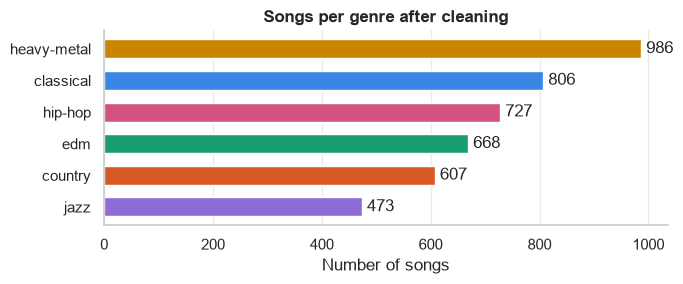

In [6]:
counts = songs.track_genre.value_counts().rename_axis("genre").to_frame("songs")
counts["share"] = (counts.songs / counts.songs.sum()).round(3)
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(counts.index[::-1], counts.songs[::-1], color=[GENRE_COLORS[g] for g in counts.index[::-1]], height=0.6)
for i, v in enumerate(counts.songs[::-1]):
    ax.text(v + 10, i, str(v), va="center")
ax.set_xlabel("Number of songs"); ax.set_title("Songs per genre after cleaning"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.savefig(FIG / "songs_per_genre.png", dpi=120); plt.show()

The genres are not perfectly balanced (heavy-metal 986 songs, jazz only 473, because jazz had the most re-releases). This mild imbalance is why later notebooks report **macro F1** (every genre counts equally) and use a **stratified** split.

## 4. Features and data types
These are the model inputs. Text columns (track_id, track_name, artists, album_name) are **never** inputs, only shown in the app. `popularity` is never an input either: it is used only to define the *hit* label.

In [7]:
feature_table = pd.DataFrame({
    "feature": ["danceability", "energy", "loudness", "speechiness", "acousticness", "instrumentalness",
                "liveness", "valence", "tempo", "duration_ms", "explicit", "mode", "key", "time_signature"],
    "type": ["numeric"] * 10 + ["binary (yes/no)", "binary (major/minor)", "categorical (12 keys)", "categorical"],
    "range in our data": [f"{songs[c].min():.2f} – {songs[c].max():.2f}" for c in
                          ["danceability", "energy", "loudness", "speechiness", "acousticness",
                           "instrumentalness", "liveness", "valence", "tempo", "duration_ms"]]
                         + ["0 / 1", "0 / 1", "0 – 11", "0, 1, 3, 4, 5"],
    "how we encode it": ["scaled"] * 10 + ["0/1, scaled", "0/1, scaled", "one-hot (11 columns)", "one-hot (3 columns)"],
})
feature_table

,feature,type,range in our data,how we encode it
0,danceability,numeric,0.00 – 0.96,scaled
1,energy,numeric,0.00 – 1.00,scaled
2,loudness,numeric,-41.53 – 0.37,scaled
3,speechiness,numeric,0.00 – 0.91,scaled
4,acousticness,numeric,0.00 – 1.00,scaled
5,instrumentalness,numeric,0.00 – 0.98,scaled
6,liveness,numeric,0.02 – 0.99,scaled
7,valence,numeric,0.00 – 0.98,scaled
8,tempo,numeric,0.00 – 214.02,scaled
9,duration_ms,numeric,17453.00 – 2646866.00,scaled


### Encoding categories
`key` is one-hot encoded into 11 yes/no columns (key C is the "baseline": a song in C has all eleven columns = 0; dropping one column avoids redundant information). `mode` has only two categories, so one 0/1 column is already its one-hot encoding. `time_signature` is 4/4 for 88% of songs but only 69% of classical songs, so it carries genre information; we keep it as 3 columns (3/4, 5/4, other; 4/4 is the baseline). Here is one song before and after encoding:

In [8]:
names = data.load_feature_names()
example = songs.iloc[0]
print("Song:", example.track_name, "–", example.artists, "| key =", example.key, data.KEY_NAMES[example.key],
      "| time_signature =", example.time_signature)
print("Encoded key columns:", {c: int(example[c]) for c in names if c.startswith("key_")})
print(f"Total input features after encoding: {len(names)}")
print(names)

Song: Zara Zara – Bombay Jayashri | key = 11 B | time_signature = 4
Encoded key columns: {'key_C#': 0, 'key_D': 0, 'key_D#': 0, 'key_E': 0, 'key_F': 0, 'key_F#': 0, 'key_G': 0, 'key_G#': 0, 'key_A': 0, 'key_A#': 0, 'key_B': 1}
Total input features after encoding: 26
['danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_ms', 'explicit', 'mode', 'key_C#', 'key_D', 'key_D#', 'key_E', 'key_F', 'key_F#', 'key_G', 'key_G#', 'key_A', 'key_A#', 'key_B', 'time_sig_3', 'time_sig_5', 'time_sig_other']


## 5. Train/test split (stratified 80/20, shared by everyone)
`src/data.py` split the songs once, with `random_state=42`, and saved which songs are train and which are test. Every notebook loads the same split.

In [9]:
X_train, X_test, y_train, y_test, feature_names = data.load_splits()
print(f"Train: {len(X_train)} songs   Test: {len(X_test)} songs")
props = pd.DataFrame({"train share": y_train["genre"].value_counts(normalize=True),
                      "test share": y_test["genre"].value_counts(normalize=True)})
props["difference"] = (props["train share"] - props["test share"]).abs()
props.round(3)

Train: 3413 songs   Test: 854 songs


,train share,test share,difference
track_genre,,,
heavy-metal,0.231,0.231,0.000
classical,0.189,0.189,0.000
hip-hop,0.170,0.171,0.001
edm,0.156,0.157,0.000
country,0.142,0.142,0.001
jazz,0.111,0.111,0.000


Because the split is **stratified**, every genre has the same share in train and test (differences below 0.1 percentage points). So a model is not judged on a test set with a different genre mix than it learned from.

## 6. Scaling, and why the scaler sees only the training set
Below: tempo and danceability before and after scaling. The scaler's mean and spread were computed on the **training songs only**. Check: training features now have mean 0 and standard deviation 1 exactly; test features are close to 0 and 1 but not exact, which is what we expect, since the test set had no say in the scaling.

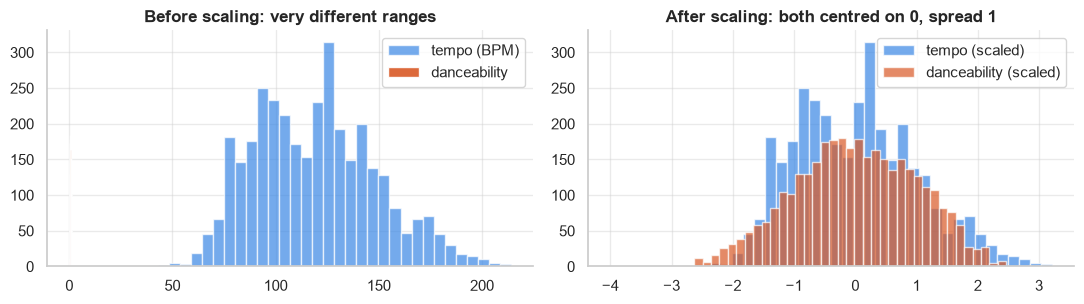

,train mean,train std,test mean,test std
danceability,0.0,1.0,0.030,1.002
energy,0.0,1.0,0.040,1.001
loudness,0.0,1.0,0.017,1.004
speechiness,-0.0,1.0,-0.018,1.005
acousticness,0.0,1.0,-0.033,1.000
instrumentalness,-0.0,1.0,0.013,1.024
liveness,-0.0,1.0,0.028,1.038
valence,0.0,1.0,0.047,0.970
tempo,0.0,1.0,0.118,1.007
duration_ms,-0.0,1.0,0.073,1.526


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
tr = songs.split == "train"
axes[0].hist(songs.loc[tr, "tempo"], bins=40, alpha=.7, label="tempo (BPM)", color="#3987e5")
axes[0].hist(songs.loc[tr, "danceability"], bins=40, alpha=.9, label="danceability", color="#d95926")
axes[0].set_title("Before scaling: very different ranges"); axes[0].legend()
axes[1].hist(X_train["tempo"], bins=40, alpha=.7, label="tempo (scaled)", color="#3987e5")
axes[1].hist(X_train["danceability"], bins=40, alpha=.7, label="danceability (scaled)", color="#d95926")
axes[1].set_title("After scaling: both centred on 0, spread 1"); axes[1].legend()
plt.tight_layout(); plt.savefig(FIG / "scaling.png", dpi=120); plt.show()

check = pd.DataFrame({"train mean": X_train[data.AUDIO_FEATURES].mean(), "train std": X_train[data.AUDIO_FEATURES].std(ddof=0),
                      "test mean": X_test[data.AUDIO_FEATURES].mean(), "test std": X_test[data.AUDIO_FEATURES].std(ddof=0)})
check.round(3)

Before scaling, tempo (around 60–200) completely dwarfs danceability (0–1): on the left plot danceability is squashed into a single bar near 0. After scaling both are on the same footing. The table confirms the train means are 0 and stds 1, while the test values are only *close* to that, proof that the test songs did not influence the scaler.

## 7. Correlation heatmap
Correlation (−1 to +1) measures how strongly two features move together. Strong correlations mean some features carry overlapping information, which is exactly what PCA will exploit.

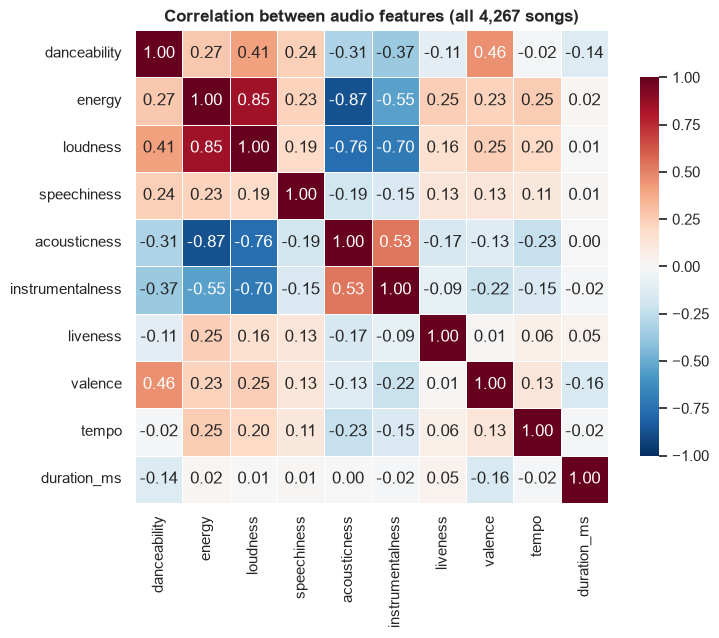

In [11]:
corr = songs[data.AUDIO_FEATURES].corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True,
            linewidths=.5, cbar_kws={"shrink": .8}, ax=ax)
ax.set_title("Correlation between audio features (all 4,267 songs)")
plt.tight_layout(); plt.savefig(FIG / "correlation_heatmap.png", dpi=120); plt.show()

This shows three strongly linked features: **energy and loudness (+0.85)** move together, and both are the opposite of **acousticness (−0.87 and −0.76)**; instrumentalness also leans to the acoustic side. In plain words, there is one big "loud and electric ↔ quiet and acoustic" axis in our data. Danceability and valence are moderately linked (+0.46: danceable songs tend to sound happier), while liveness, tempo and duration are almost independent of everything else.

## 8. Feature distributions per genre
How do key features differ between genres? Each box shows the middle 50% of songs in a genre; the line inside is the median.

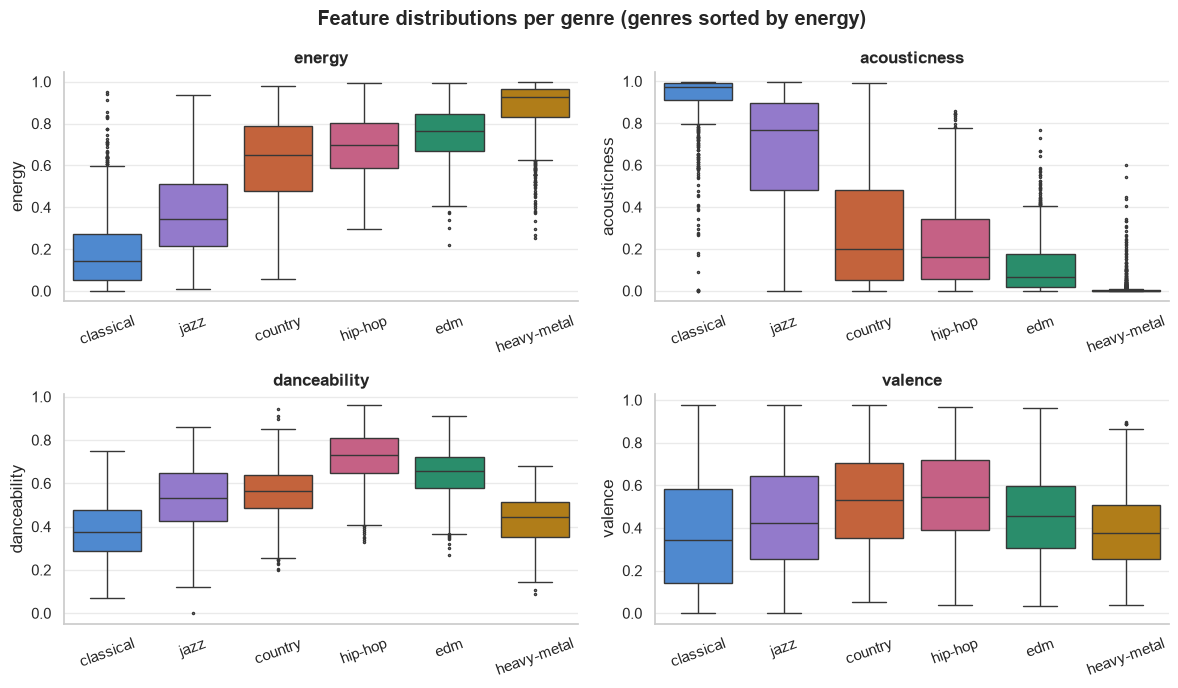

In [12]:
order = list(genre_means.sort_values("energy").index)
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, feat in zip(axes.ravel(), ["energy", "acousticness", "danceability", "valence"]):
    sns.boxplot(data=songs, x="track_genre", y=feat, order=order, hue="track_genre", palette=GENRE_COLORS,
                ax=ax, fliersize=1.5, linewidth=1, legend=False)
    ax.set_title(feat); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=20)
plt.suptitle("Feature distributions per genre (genres sorted by energy)", fontweight="bold")
plt.tight_layout(); plt.savefig(FIG / "distributions_per_genre.png", dpi=120); plt.show()

This shows that **energy and acousticness separate the genres best**: classical sits at the bottom of energy and top of acousticness, heavy-metal at the opposite extreme, with jazz, country, hip-hop and edm in between. **Danceability** singles out hip-hop (highest) and edm, while classical and heavy-metal are the least danceable. **Valence** overlaps a lot across genres (every genre has happy and sad songs), a hint that predicting happiness (P2) is harder than predicting genre.

## 9. PCA: compressing the features
We run PCA on the 10 continuous **audio features** (scaled). We leave out the 14 one-hot key/time-signature columns here: each is an on/off switch that would add its own separate "direction" and make the map about musical key rather than about how a song sounds.

To keep things leak-free, PCA is **fit on the training songs only** and then applied to all songs (P6 later uses these components as model inputs).

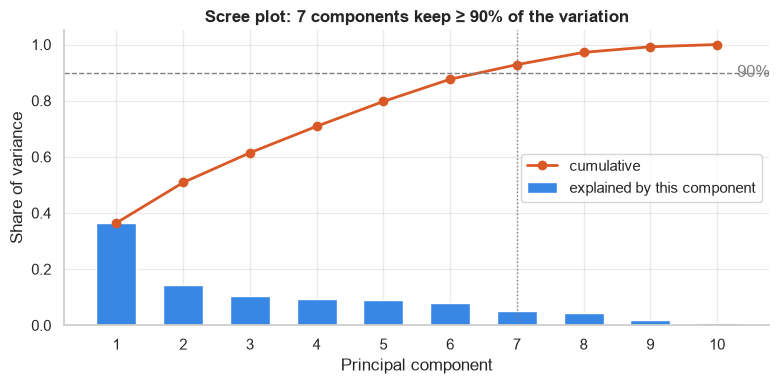

component,1,2,3,4,5,6,7,8,9,10
explained,0.365,0.144,0.106,0.094,0.089,0.079,0.052,0.044,0.020,0.008
cumulative,0.365,0.509,0.614,0.709,0.797,0.876,0.928,0.972,0.992,1.000


In [13]:
A = data.AUDIO_FEATURES
pca = PCA(random_state=42).fit(X_train[A])
evr = pca.explained_variance_ratio_
cum = np.cumsum(evr)
n90 = int(np.argmax(cum >= 0.90) + 1)

fig, ax = plt.subplots(figsize=(8, 4))
comps = np.arange(1, len(evr) + 1)
ax.bar(comps, evr, color="#3987e5", width=0.6, label="explained by this component")
ax.plot(comps, cum, marker="o", color="#d95926", lw=2, label="cumulative")
ax.axhline(0.9, ls="--", color="gray", lw=1); ax.text(len(evr) + 0.3, 0.9, "90%", va="center", color="gray")
ax.axvline(n90, ls=":", color="gray", lw=1)
ax.set_xticks(comps); ax.set_xlabel("Principal component"); ax.set_ylabel("Share of variance")
ax.set_title(f"Scree plot: {n90} components keep ≥ 90% of the variation"); ax.legend(loc="center right")
plt.tight_layout(); plt.savefig(FIG / "scree_plot.png", dpi=120); plt.show()
pd.DataFrame({"component": comps, "explained": evr.round(3), "cumulative": cum.round(3)}).set_index("component").T

This shows that **PC1 alone keeps 36.5%** of all variation and the first two together keep 51%. So the 2D Song Map shows about half of the information. To keep **at least 90% we need 7 of the 10 components**. The last two components add almost nothing (2% and 0.8%), because they mostly repeat the energy/loudness/acousticness information.

### What do PC1 and PC2 mean? (loadings)
Each component is a weighted mix of the original features. These weights are called **loadings**. Big positive or negative loadings tell us what the component "measures".

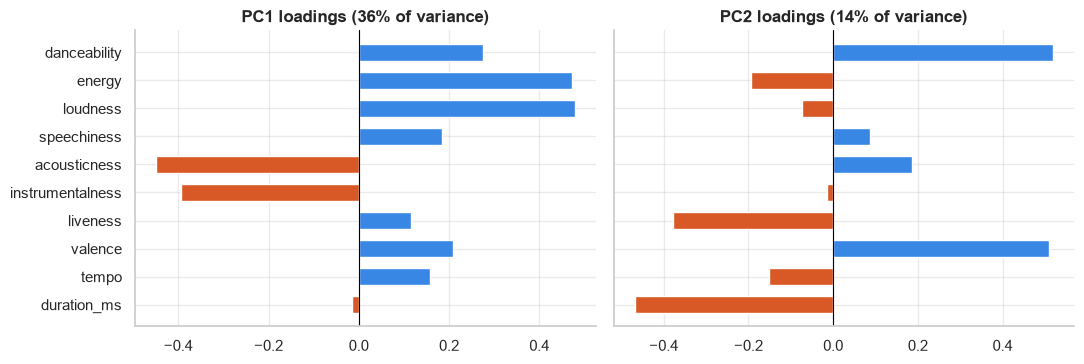

,PC1,PC2
acousticness,-0.45,0.19
instrumentalness,-0.39,-0.01
duration_ms,-0.01,-0.47
liveness,0.12,-0.38
tempo,0.16,-0.15
speechiness,0.18,0.09
valence,0.21,0.51
danceability,0.28,0.52
energy,0.47,-0.19
loudness,0.48,-0.07


In [14]:
loadings = pd.DataFrame(pca.components_[:2].T, index=A, columns=["PC1", "PC2"])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, pc in zip(axes, ["PC1", "PC2"]):
    vals = loadings[pc]
    ax.barh(A, vals, color=["#3987e5" if v > 0 else "#d95926" for v in vals], height=0.6)
    ax.axvline(0, color="black", lw=.8); ax.set_title(f"{pc} loadings ({evr[int(pc[-1]) - 1]:.0%} of variance)")
axes[0].invert_yaxis()
plt.tight_layout(); plt.savefig(FIG / "pca_loadings.png", dpi=120); plt.show()
loadings.round(2).sort_values("PC1")

This shows that **PC1 is an "intensity" axis**: loudness (+0.48) and energy (+0.47) on the positive side, acousticness (−0.45) and instrumentalness (−0.39) on the negative side. High PC1 = loud, energetic, electric; low PC1 = quiet, acoustic, instrumental. **PC2 is roughly a "danceable and happy vs long and live" axis**: danceability (+0.52) and valence (+0.51) push it up, duration (−0.47) and liveness (−0.38) push it down.

### The 2D Song Map
Every song projected onto PC1 and PC2, coloured by genre.

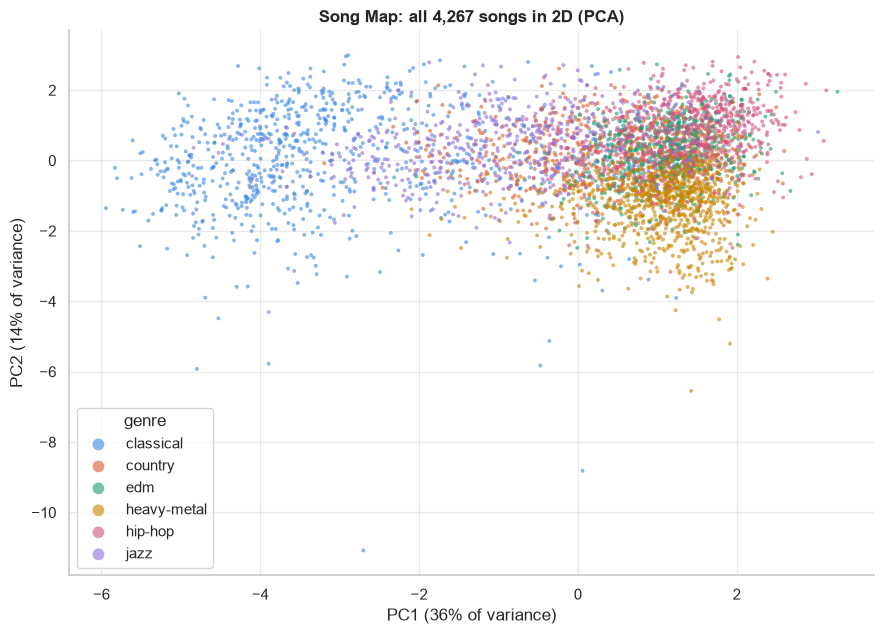

In [15]:
coords = pca.transform(X_all[A])[:, :2]
song_map = pd.DataFrame({"pc1": coords[:, 0], "pc2": coords[:, 1]}, index=songs.index)
fig, ax = plt.subplots(figsize=(9, 6.5))
for g in data.GENRES:
    m = songs.track_genre == g
    ax.scatter(song_map.pc1[m], song_map.pc2[m], s=8, alpha=.6, color=GENRE_COLORS[g], label=g, edgecolors="none")
ax.set_xlabel(f"PC1 ({evr[0]:.0%} of variance)"); ax.set_ylabel(f"PC2 ({evr[1]:.0%} of variance)")
ax.set_title("Song Map: all 4,267 songs in 2D (PCA)"); ax.legend(markerscale=3, title="genre")
plt.tight_layout(); plt.savefig(FIG / "song_map_genre.png", dpi=120); plt.show()

This shows that classical (blue) forms its own region on the left (low intensity), jazz sits between classical and the rest, and the four "loud" genres crowd together on the right. Heavy-metal (amber) drifts lower (less danceable), hip-hop (magenta) and edm (green) higher (more danceable and happier). Country, edm and hip-hop overlap heavily in 2D, so we expect those three to be the genres models confuse most; remember this map only shows 51% of the information.

## 10. DBSCAN: finding unusual songs
DBSCAN runs on the same 10 scaled audio features (full 10-D space, not the 2D map, so no information is lost). We use `min_samples = 20` (a common rule of thumb is 2 × the number of features).

**Choosing `eps` with a k-distance plot:** for every song we measure the distance to its 20th nearest neighbour and sort these distances. Most songs have a small value (they live in a crowd); at some point the curve bends sharply upwards: those are the isolated songs. We set `eps` at that bend ("elbow"), found automatically as the point farthest from the straight line joining the curve's two ends.

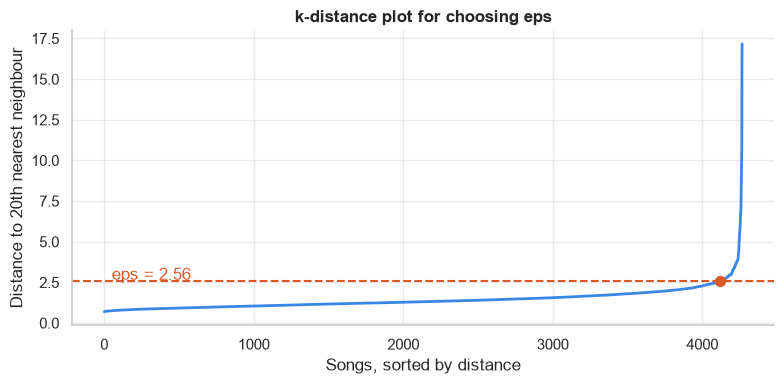

Chosen eps: 2.56


In [16]:
MIN_SAMPLES = 20
Xa = X_all[A].values
nn = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(Xa)
kdist = np.sort(nn.kneighbors(Xa)[0][:, -1])
# elbow = point farthest from the straight line joining the first and last point
# (both axes rescaled to 0-1 first, so the answer does not depend on units)
x = np.arange(len(kdist))
xn, yn = x / x[-1], (kdist - kdist[0]) / (kdist[-1] - kdist[0])
dist_to_line = np.abs(xn - yn) / np.sqrt(2)          # distance to the diagonal y = x
elbow = int(np.argmax(dist_to_line)); EPS = float(round(kdist[elbow], 2))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(x, kdist, color="#3987e5", lw=2)
ax.axhline(EPS, ls="--", color="#d95926"); ax.scatter([elbow], [kdist[elbow]], color="#d95926", zorder=3, s=50)
ax.text(50, EPS + 0.1, f"eps = {EPS}", color="#d95926")
ax.set_xlabel("Songs, sorted by distance"); ax.set_ylabel(f"Distance to {MIN_SAMPLES}th nearest neighbour")
ax.set_title("k-distance plot for choosing eps")
plt.tight_layout(); plt.savefig(FIG / "k_distance.png", dpi=120); plt.show()
print("Chosen eps:", EPS)

This shows the typical "hockey stick": for about 98% of songs the distance to the 20th neighbour stays below ~2.5, then it shoots up for a small number of very isolated songs. The elbow gives **eps = 2.56**: a song needs 20 neighbours within this radius to count as "in a crowd".

In [17]:
db = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit(Xa)
labels = db.labels_
is_core = np.zeros(len(labels), bool); is_core[db.core_sample_indices_] = True
is_noise = labels == -1
summary = pd.Series({"clusters found": len(set(labels)) - (1 if -1 in labels else 0),
                     "core points": int(is_core.sum()),
                     "border points": int((~is_core & ~is_noise).sum()),
                     "noise points (unusual songs)": int(is_noise.sum()),
                     "noise share": f"{is_noise.mean():.1%}"})
print(summary.to_string())
print("\nUnusual songs per genre:")
print(songs[is_noise].track_genre.value_counts().to_string())

clusters found                     1
core points                     4114
border points                     94
noise points (unusual songs)      59
noise share                     1.4%

Unusual songs per genre:
track_genre
classical      35
heavy-metal    10
jazz           10
hip-hop         4


This shows that with these settings DBSCAN finds **one big dense group** (most songs are connected through crowded neighbourhoods; genres blend into each other in feature space) and **59 noise points (1.4%)**: our unusual songs. Most of them are classical (35). For outlier detection, one cluster plus noise is exactly what we want: DBSCAN is used here to find the odd ones out, not to find genres.

### Five example unusual songs
The most isolated noise points (largest distance to their 20th neighbour), with the features that make them odd. A z-score above +3 or below −3 means "more than 3 standard deviations from the average song".

In [18]:
song_kdist = nn.kneighbors(Xa)[0][:, -1]
odd_idx = songs.index[is_noise][np.argsort(-song_kdist[is_noise])[:5]]
rows = []
for i in odd_idx:
    z = X_all.loc[i, A]
    top = z.abs().sort_values(ascending=False).index[:2]
    rows.append({"song": songs.loc[i, "track_name"][:40], "artist": songs.loc[i, "artists"][:30],
                 "genre": songs.loc[i, "track_genre"],
                 "why unusual": ", ".join(f"{f} {'high' if z[f] > 0 else 'low'} (z={z[f]:+.1f})" for f in top)})
pd.DataFrame(rows)

,song,artist,genre,why unusual
0,Chanting of the Gayatri Mantra 108 Times,Pandit Jasraj,classical,"duration_ms high (z=+22.5), danceability low (..."
1,Ram Ram Jai Raja Ram Ram Ram Jai Sita Ra,Rattan Mohan Sharma,classical,"duration_ms high (z=+21.5), valence high (z=+1.4)"
2,Sri Venkatesa Suprabhatam,M. S. Subbulakshmi;T. K. Murth,classical,"speechiness high (z=+9.8), duration_ms high (z..."
3,Vishnu Sahasranamam - Dhyanam,M. S. Subbulakshmi,classical,"duration_ms high (z=+14.6), speechiness high (..."
4,Lalitha Sahasranama Sthothram,Priya Sisters,classical,"duration_ms high (z=+14.2), valence high (z=+1.4)"


This shows that the most unusual songs are **long Indian devotional recordings** (chants and hymns listed under "classical"). The top one, a chant of the Gayatri Mantra 108 times, is more than 22 standard deviations longer than an average song, and some have very high speechiness (spoken word). They really are unlike the rest of our music, so the outlier detection makes musical sense.

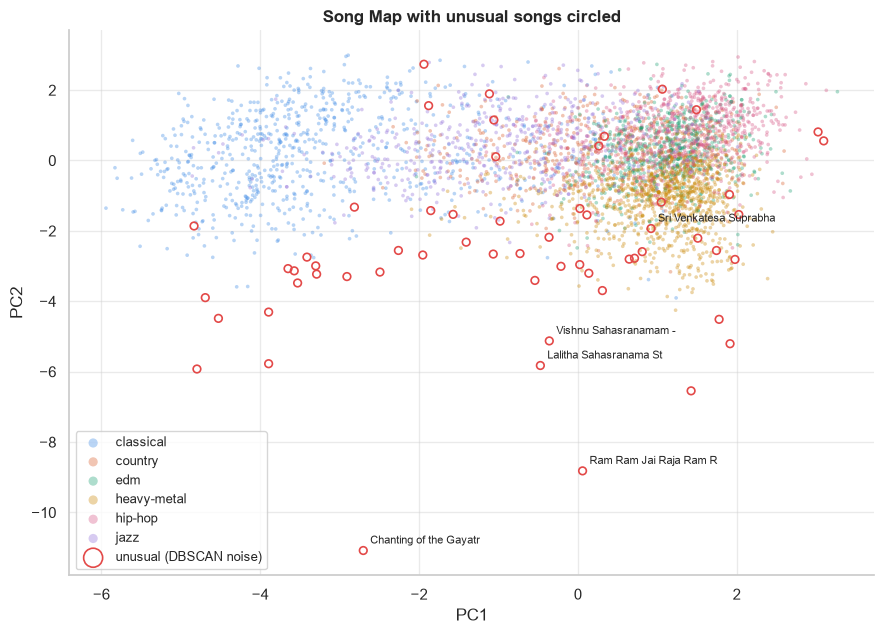

In [19]:
fig, ax = plt.subplots(figsize=(9, 6.5))
for g in data.GENRES:
    m = (songs.track_genre == g).values & ~is_noise
    ax.scatter(song_map.pc1[m], song_map.pc2[m], s=7, alpha=.35, color=GENRE_COLORS[g], label=g, edgecolors="none")
ax.scatter(song_map.pc1[is_noise], song_map.pc2[is_noise], s=30, facecolors="none", edgecolors=OUTLIER,
           linewidths=1.2, label="unusual (DBSCAN noise)")
for i in odd_idx:
    ax.annotate(songs.loc[i, "track_name"][:22], (song_map.loc[i, "pc1"], song_map.loc[i, "pc2"]),
                fontsize=8, xytext=(5, 5), textcoords="offset points")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.legend(markerscale=2.5, fontsize=9)
ax.set_title("Song Map with unusual songs circled")
plt.tight_layout(); plt.savefig(FIG / "song_map_outliers.png", dpi=120); plt.show()

This shows the unusual songs mostly sit at the **bottom of the map (very low PC2)**, which is the "long and live" direction, and on the fringes of the clouds. A few circled songs appear inside a crowd on the 2D map: they are unusual in one of the dimensions the 2D map hides (remember the map shows only about half of the information).

## 11. Save for the app and the other notebooks
- `models/p1_song_map/pca.joblib`: the PCA fitted on training songs (all 10 components; P6 uses the first `n90`).
- `models/p1_song_map/song_map.csv`: PC1/PC2 coordinates and the DBSCAN outlier flag for every song (the app's Song Map and P7 use it).
- `models/p1_song_map/song_map_info.json`: settings and key numbers.

In [20]:
song_map["is_outlier"] = is_noise.astype(int)
song_map["dbscan_label"] = labels
song_map.to_csv(MODELS / "song_map.csv")
joblib.dump(pca, MODELS / "pca.joblib")
info = {"pca_features": A, "explained_variance_ratio": evr.round(4).tolist(), "n_components_90": n90,
        "dbscan_eps": EPS, "dbscan_min_samples": MIN_SAMPLES, "n_outliers": int(is_noise.sum()),
        "pc1_top_loadings": loadings.PC1.abs().sort_values(ascending=False).index[:3].tolist(),
        "pc2_top_loadings": loadings.PC2.abs().sort_values(ascending=False).index[:3].tolist()}
(MODELS / "song_map_info.json").write_text(json.dumps(info, indent=2))
print(json.dumps(info, indent=2))

{
  "pca_features": [
    "danceability",
    "energy",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo",
    "duration_ms"
  ],
  "explained_variance_ratio": [
    0.3647,
    0.1438,
    0.1059,
    0.0943,
    0.0886,
    0.0792,
    0.0519,
    0.0437,
    0.0199,
    0.0081
  ],
  "n_components_90": 7,
  "dbscan_eps": 2.56,
  "dbscan_min_samples": 20,
  "n_outliers": 59,
  "pc1_top_loadings": [
    "loudness",
    "energy",
    "acousticness"
  ],
  "pc2_top_loadings": [
    "danceability",
    "valence",
    "duration_ms"
  ]
}


## Results summary

| Item | Value |
|---|---|
| Raw rows / genres | 114,000 / 114 |
| Songs kept (6 genres, duplicates removed) | **4,267** |
| Train / test songs | 3,413 / 854 (stratified 80/20) |
| Model input features after encoding | 26 |
| PCA: variance kept by PC1 / PC1+PC2 | 36.5% / 51% |
| PCA: components for ≥ 90% variance | **7 of 10** |
| DBSCAN settings | eps = 2.56, min_samples = 20 |
| Unusual songs (noise) | **59 (1.4%)** |

**Takeaways**
- Cleaning mattered: 1,615 re-released duplicates were removed, so almost no song appears in both train and test (13 near-duplicates with slightly different titles remain; see the check in section 3).
- The scaler is fit on training songs only; test features are close to (but not exactly) mean 0 / std 1, proof there is no leakage.
- The biggest pattern in the data is "loud & energetic vs quiet & acoustic" (PC1), which separates classical and jazz from the rest.
- Country, edm and hip-hop overlap on the map, so they will be the hardest genres to tell apart.
- The unusual songs are mostly very long devotional recordings: DBSCAN finds songs that really are different.

## Questions you may be asked

**1. Why scale before PCA? Why fit the scaler only on the training set?**
PCA looks for directions of largest variance. Unscaled, `duration_ms` (variance in the billions) and `tempo` would hog the first components just because their numbers are big, not because they matter. Scaling puts every feature on the same footing. The scaler is fit on training songs only so that no information from the test songs (their averages) leaks into training; otherwise test scores would be slightly optimistic.

**2. What does the first principal component represent in our data?**
An "intensity" axis: loud, energetic songs (high loudness and energy) at one end and quiet, acoustic, instrumental songs at the other. It explains 36.5% of the variation and separates classical (low PC1) from heavy-metal, edm and hip-hop (high PC1).

**3. How many components did we need, and what did we lose?**
7 of the 10 components keep 90% of the variation. The remaining 3 components (about 7%) are lost; they are mostly small leftovers of features that already overlap (energy, loudness, acousticness). For the 2D map we use only 2 components, which keep 51%, so points that look close on the map can still differ in hidden directions (e.g. some "unusual" songs look normal on the map).

**4. Why DBSCAN for outliers instead of k-means?**
k-means must put *every* song into some cluster (it has no idea of "noise") and needs the number of clusters in advance; it also assumes round clusters. DBSCAN finds dense regions of any shape on its own and explicitly labels songs that are in no dense region as noise, which is exactly our definition of "unusual".

**5. Why only 6 genres?**
Many of the 114 genres are near-duplicates (rock / alt-rock / hard-rock) that even listeners disagree on, so a model could never separate them from audio features. Six clearly different genres give a meaningful task, about 4,300 songs (fast to train for every model, including SVMs and hierarchical clustering) and readable plots. The proposal planned "about 6 clearly different genres" for the same reason.